# Домашнее задание к занятию «Классификация: Логистическая регрессия и SVM»

**Автор:** Александра Бужор (Telegram: [@Angry_C_F_O](https://t.me/Angry_C_F_O))

**Задача:** бинарная классификация физических лиц по уровню дохода (`income`: `<=50K` / `>50K`) на датасете [Adult (UCI Machine Learning Repository)](https://archive.ics.uci.edu/dataset/2/adult) с помощью **логистической регрессии** и **метода опорных векторов (SVM)**.

**План работы**

1. Загрузка данных
2. Первичный анализ: пропуски и дубликаты, визуализация, преобразование категориальных признаков
3. Разделение выборки на обучающую (80%) и тестовую (20%)
4. Обучение логистической регрессии и SVM
5. Предсказание на тестовой выборке и оценка точности через `score`
6. Дополнительные эксперименты: другой способ работы с пропусками, учёт дисбаланса классов, сравнение с другими моделями
7. Выводы

## 0. Импорт библиотек и настройки

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
import seaborn as sns

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             recall_score, precision_score, f1_score)

warnings.filterwarnings("ignore", category=FutureWarning)
set_config(display="text")      # компактный вывод моделей (корректно отображается на GitHub)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

# Единая палитра графиков: класс <=50K — синий, класс >50K — оранжевый
COLOR_LOW, COLOR_HIGH = "#2a78d6", "#eb6834"
CLASS_COLORS = {"<=50K": COLOR_LOW, ">50K": COLOR_HIGH}
plt.rcParams.update({
    "figure.figsize": (12, 6), "figure.dpi": 100,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e3de", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "xtick.labelsize": 11, "ytick.labelsize": 11,
    "text.color": "#0b0b0b", "legend.fontsize": 11, "legend.frameon": False,
})

## 1. Загрузка данных

Данные взяты из архива UCI, приложенного к заданию. В архиве два файла без заголовков:

- `adult.data` — 32 561 запись;
- `adult.test` — 16 281 запись. В первой строке служебный комментарий, а метки класса записаны с точкой на конце (`<=50K.`).

Файлы объединяем в один датасет на 48 842 записи. Это тот же набор, что лежит в `adult.csv`. На обучающую и тестовую части делим позже сами, в пропорции 80/20, как требует задание.

Названия столбцов взяты из описания датасета (`adult.names`). В значениях после запятой стоит пробел, его убирает параметр `skipinitialspace=True`.

Если ноутбук запущен без папки `data/` (например, в Google Colab), данные скачиваются напрямую с сайта UCI.

In [2]:
COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num",
           "marital-status", "occupation", "relationship", "race", "sex",
           "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

DATA_DIR = Path("data")
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"

def read_part(file_name, skiprows=0):
    source = DATA_DIR / file_name if (DATA_DIR / file_name).exists() else UCI_URL + file_name
    return pd.read_csv(source, header=None, names=COLUMNS,
                       skipinitialspace=True, skiprows=skiprows)

df_train_part = read_part("adult.data")
df_test_part = read_part("adult.test", skiprows=1)   # пропускаем строку '|1x3 Cross validator'

df = pd.concat([df_train_part, df_test_part], ignore_index=True)
df["income"] = df["income"].str.rstrip(".")           # '<=50K.' -> '<=50K'

print(f"adult.data: {df_train_part.shape}, adult.test: {df_test_part.shape}")
print(f"Объединённый датасет: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.head()

adult.data: (32561, 15), adult.test: (16281, 15)
Объединённый датасет: 48842 строк, 15 столбцов


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


Статистики по числовым признакам:

In [4]:
df.describe().round(1)

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.0,48842.0,48842.0,48842.0,48842.0,48842.0
mean,38.6,189664.1,10.1,1079.1,87.5,40.4
std,13.7,105604.0,2.6,7452.0,403.0,12.4
min,17.0,12285.0,1.0,0.0,0.0,1.0
25%,28.0,117550.5,9.0,0.0,0.0,40.0
50%,37.0,178144.5,10.0,0.0,0.0,40.0
75%,48.0,237642.0,12.0,0.0,0.0,45.0
max,90.0,1490400.0,16.0,99999.0,4356.0,99.0


Количество уникальных значений и примеры значений по каждому категориальному признаку:

In [5]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
for col in cat_cols:
    values = df[col].unique()
    print(f"{col:15s} | уникальных: {len(values):2d} | {list(values[:8])}{' ...' if len(values) > 8 else ''}")

workclass       | уникальных:  9 | ['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov', 'Local-gov', '?', 'Self-emp-inc', 'Without-pay'] ...
education       | уникальных: 16 | ['Bachelors', 'HS-grad', '11th', 'Masters', '9th', 'Some-college', 'Assoc-acdm', 'Assoc-voc'] ...
marital-status  | уникальных:  7 | ['Never-married', 'Married-civ-spouse', 'Divorced', 'Married-spouse-absent', 'Separated', 'Married-AF-spouse', 'Widowed']
occupation      | уникальных: 15 | ['Adm-clerical', 'Exec-managerial', 'Handlers-cleaners', 'Prof-specialty', 'Other-service', 'Sales', 'Craft-repair', 'Transport-moving'] ...


relationship    | уникальных:  6 | ['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried', 'Other-relative']
race            | уникальных:  5 | ['White', 'Black', 'Asian-Pac-Islander', 'Amer-Indian-Eskimo', 'Other']
sex             | уникальных:  2 | ['Male', 'Female']
native-country  | уникальных: 42 | ['United-States', 'Cuba', 'Jamaica', 'India', '?', 'Mexico', 'South', 'Puerto-Rico'] ...
income          | уникальных:  2 | ['<=50K', '>50K']


In [6]:
print("Распределение целевой переменной:")
pd.concat([df["income"].value_counts(), df["income"].value_counts(normalize=True).round(4)],
          axis=1, keys=["количество", "доля"])

Распределение целевой переменной:


,количество,доля
income,,
<=50K,37155,0.7607
>50K,11687,0.2393


**Что видно на первом шаге**

- 6 числовых признаков (`age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`) и 8 категориальных, плюс целевая `income`.
- `capital-gain` и `capital-loss` у большинства людей равны нулю: медиана 0, а максимум у `capital-gain` достигает 99 999. Распределения сильно скошены.
- Классы несбалансированы: людей с доходом `>50K` примерно четверть.
- `df.info()` не показывает пропусков (`NaN`), но в категориальных признаках есть значение `?`. Это и есть пропуски, проверим их отдельно.

## 2. Первичный анализ

### 2a. Пропуски и дубликаты

In [7]:
print("Пропусков в виде NaN:", df.isna().sum().sum())
print("\nЗначений '?' по столбцам:")
question_marks = (df == "?").sum()
print(question_marks[question_marks > 0])

Пропусков в виде NaN: 0

Значений '?' по столбцам:


workclass         2799
occupation        2809
native-country     857
dtype: int64


In [8]:
df = df.replace("?", np.nan)

missing = pd.DataFrame({"пропусков": df.isna().sum(),
                        "доля, %": (df.isna().mean() * 100).round(2)})
display(missing[missing["пропусков"] > 0])

rows_with_na = df.isna().any(axis=1)
print(f"Строк хотя бы с одним пропуском: {rows_with_na.sum()} ({rows_with_na.mean():.1%} датасета)")
print(f"Доля дохода >50K в строках с пропусками: {(df.loc[rows_with_na, 'income'] == '>50K').mean():.1%}, "
      f"без пропусков: {(df.loc[~rows_with_na, 'income'] == '>50K').mean():.1%}")

,пропусков,"доля, %"
workclass,2799,5.73
occupation,2809,5.75
native-country,857,1.75


Строк хотя бы с одним пропуском: 3620 (7.4% датасета)
Доля дохода >50K в строках с пропусками: 13.2%, без пропусков: 24.8%


Пропуски есть только в трёх категориальных признаках: `workclass` (тип занятости), `occupation` (род занятий) и `native-country` (страна происхождения). Строк с пропусками 7,4%. Это немного, поэтому, как требует задание, **удаляем эти строки**. После удаления остаётся 45 222 записи, что совпадает с описанием датасета.

Заодно проверяем полные дубликаты. Они могут попасть одновременно в обучающую и тестовую выборки и слегка завысить оценку качества.

In [9]:
df = df.dropna()
print("После удаления пропусков:", df.shape)

n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Удалено полных дубликатов: {n_dup}. Итоговый размер: {df.shape}")

После удаления пропусков: (45222, 15)


Удалено полных дубликатов: 47. Итоговый размер: (45175, 15)


**\* Альтернативные способы работы с пропусками**

Удалять строки проще всего, но так теряется 7,4% данных. К тому же пропуски распределены неслучайно: среди строк с пропусками доход `>50K` встречается заметно реже, чем в остальных (см. вывод выше). Варианты:

1. **Отдельная категория `Unknown`.** Для категориальных признаков это самый естественный вариант: модель сама учится на факте отсутствия значения. Здесь это особенно уместно: `workclass` и `occupation` пропущены одновременно во всех 2 799 случаях (ещё 10 пропусков `occupation` у людей с `workclass = Never-worked`), то есть это одна устойчивая группа людей.
2. **Заполнение модой** (самым частым значением): `SimpleImputer(strategy="most_frequent")`. Просто, но искажает распределение: всем людям с неизвестным типом занятости припишется `Private`, хотя по доходу они заметно отличаются от остальных.
3. **Восстановление по другим признакам**: `KNNImputer`, `IterativeImputer` или отдельная модель-классификатор, которая предсказывает пропущенную категорию по остальным столбцам.
4. **Заполнение + флаг пропуска**: признак `<столбец>_missing = 1/0` сохраняет информацию о том, что значение было неизвестно.

Первый вариант проверен на практике в разделе 6.1.

### 2b. Визуализация

**График 1. Баланс классов целевой переменной**

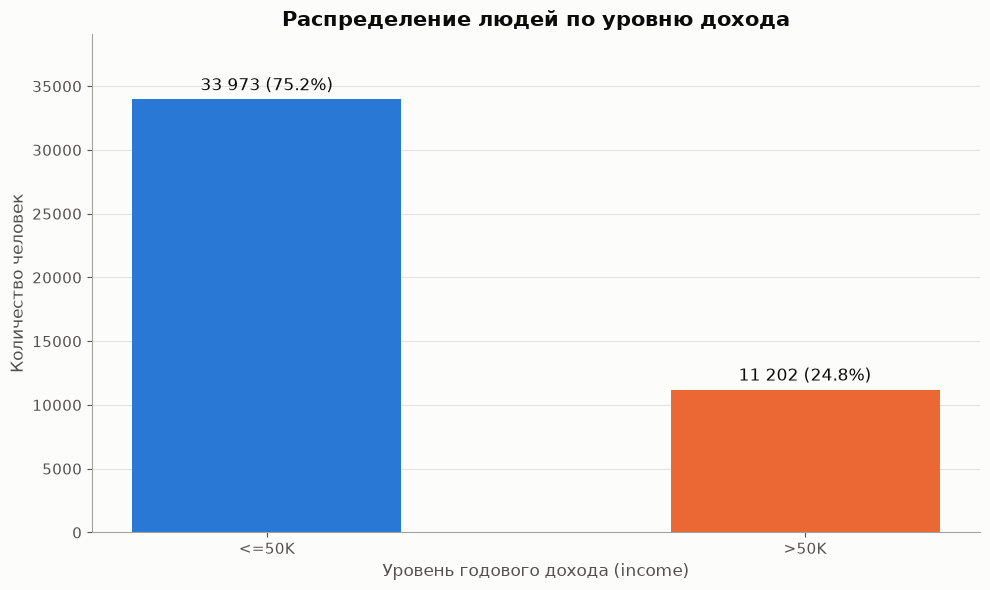

In [10]:
counts = df["income"].value_counts().reindex(["<=50K", ">50K"])
shares = counts / counts.sum()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(counts.index, counts.values, width=0.5,
              color=[CLASS_COLORS[c] for c in counts.index])
for bar, n, p in zip(bars, counts.values, shares.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 400, f"{n:,} ({p:.1%})".replace(",", " "),
            ha="center", va="bottom", fontsize=12)
ax.set_title("Распределение людей по уровню дохода")
ax.set_xlabel("Уровень годового дохода (income)")
ax.set_ylabel("Количество человек")
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Вывод.** Классы несбалансированы примерно 3 : 1, людей с доходом `>50K` около 24,8%. Значит:

- «модель», которая всегда отвечает `<=50K`, уже получит accuracy около 75%. С этим уровнем и нужно сравнивать обученные модели;
- одной accuracy для оценки мало, нужно смотреть ещё recall и precision по классу `>50K`;
- при делении на train/test нужна стратификация, чтобы доли классов в выборках совпадали.

**График 2. Распределение возраста в каждом классе дохода**

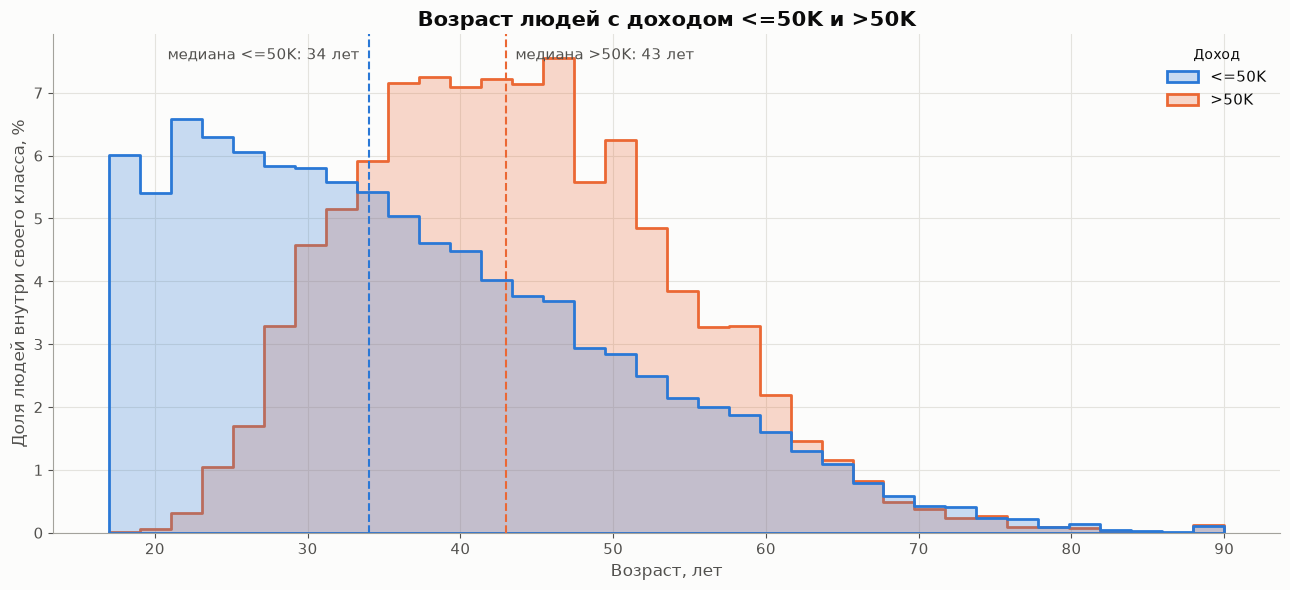

In [11]:
fig, ax = plt.subplots(figsize=(13, 6))
sns.histplot(data=df, x="age", hue="income", hue_order=["<=50K", ">50K"],
             palette=CLASS_COLORS, binwidth=2, stat="percent", common_norm=False,
             element="step", fill=True, alpha=0.25, linewidth=2, ax=ax)
for cls, offset, align in [("<=50K", -0.6, "right"), (">50K", 0.6, "left")]:
    med = df.loc[df["income"] == cls, "age"].median()
    ax.axvline(med, color=CLASS_COLORS[cls], linestyle="--", linewidth=1.5)
    ax.text(med + offset, ax.get_ylim()[1] * 0.95, f"медиана {cls}: {med:.0f} лет",
            ha=align, fontsize=11, color="#52514e")
ax.set_title("Возраст людей с доходом <=50K и >50K")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Доля людей внутри своего класса, %")
ax.get_legend().set_title("Доход")
plt.tight_layout()
plt.show()

**Вывод.** Возраст хорошо разделяет классы. Распределение класса `<=50K` смещено к молодым людям (медиана 34 года, пик около 20–25 лет). У класса `>50K` распределение уже, с пиком в 40–50 лет (медиана 43 года). Людей с высоким доходом младше 25 лет почти нет. Зависимость нелинейная: доля людей с доходом `>50K` растёт примерно до 45–50 лет (около 40% в этой группе), а после 55 лет снижается. Ядро SVM (RBF) может уловить такую зависимость, логистическая регрессия без доработки признаков нет.

**График 3. Доля людей с доходом >50K в зависимости от уровня образования**

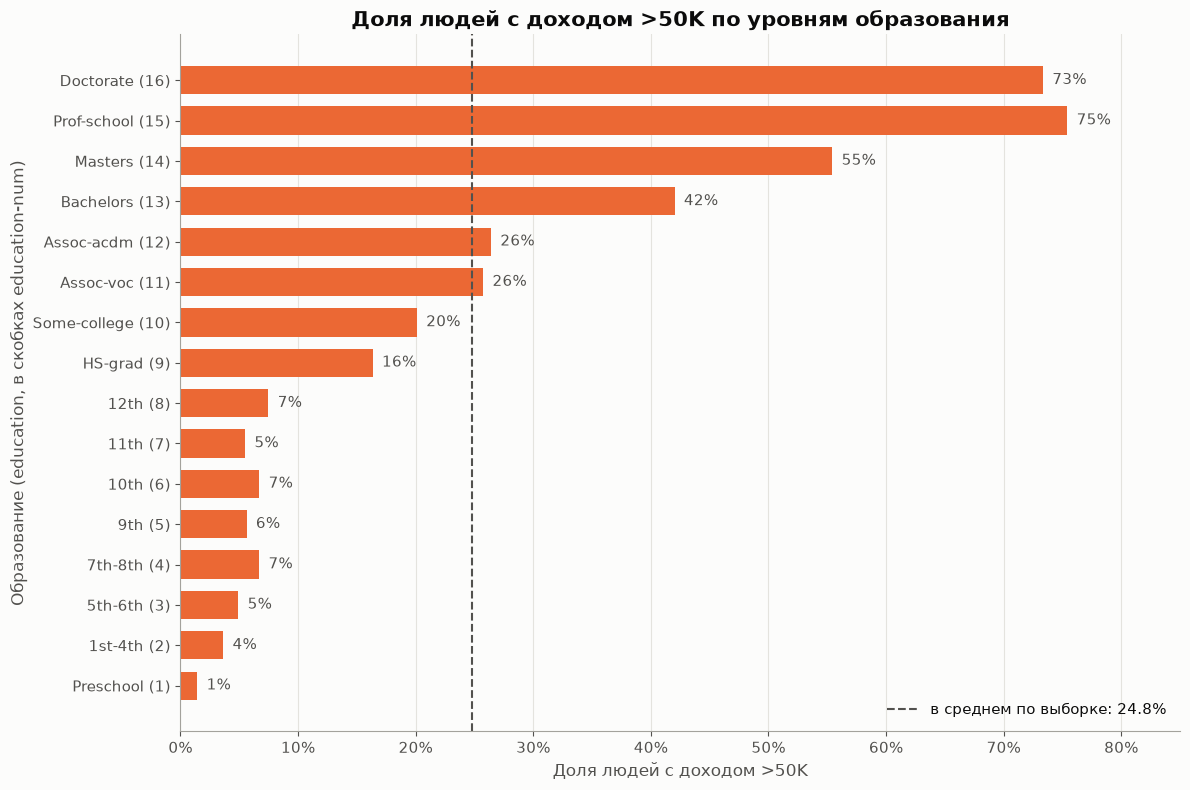

In [12]:
edu = (df.groupby(["education-num", "education"])["income"]
         .apply(lambda s: (s == ">50K").mean())
         .reset_index(name="share_high")
         .sort_values("education-num"))
overall = (df["income"] == ">50K").mean()

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(edu["education"] + " (" + edu["education-num"].astype(str) + ")",
        edu["share_high"], color=COLOR_HIGH, height=0.7)
for y, v in enumerate(edu["share_high"]):
    ax.text(v + 0.008, y, f"{v:.0%}", va="center", fontsize=10.5, color="#52514e")
ax.axvline(overall, color="#52514e", linestyle="--", linewidth=1.5,
           label=f"в среднем по выборке: {overall:.1%}")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, 0.85)
ax.set_title("Доля людей с доходом >50K по уровням образования")
ax.set_xlabel("Доля людей с доходом >50K")
ax.set_ylabel("Образование (education, в скобках education-num)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Вывод.** Чем выше уровень образования, тем больше доля высокого дохода. Без законченного школьного образования она не выше 7%, у выпускников школы (`HS-grad`) 16%, у бакалавров (`Bachelors`) около 42%, у магистров 55%, у докторов наук и выпускников профессиональных школ (`Doctorate`, `Prof-school`) 73–75%. Зависимость почти монотонная, поэтому порядковый числовой признак `education-num` хорошо подходит для линейной модели.

Отсюда видно и другое: `education` и `education-num` содержат одну и ту же информацию, каждому уровню образования соответствует ровно одно число. Один из двух признаков можно удалить без потерь.

### 2c. Преобразование признаков

Перед преобразованием проверим два кандидата на удаление:

- `education`: однозначно ли он соответствует `education-num`;
- `fnlwgt` (final weight): это статистический вес записи в переписи, то есть сколько людей в генеральной совокупности представляет эта строка. Это характеристика выборки, а не самого человека. Проверим, различается ли он между классами.

In [13]:
print("Число разных education-num на одно значение education:",
      df.groupby("education")["education-num"].nunique().max())
print("\nfnlwgt по классам:")
df.groupby("income")["fnlwgt"].agg(["mean", "median"]).round(0)

Число разных education-num на одно значение education: 1

fnlwgt по классам:


,mean,median
income,,
<=50K,190177.0,178951.0
>50K,188409.0,176756.0


Средний и медианный `fnlwgt` в двух классах практически одинаковы, признак не несёт информации о доходе. В итоге:

| Признак | Преобразование | Причина |
|---|---|---|
| `education` | удаляем | дублирует порядковый `education-num` |
| `fnlwgt` | удаляем | технический вес выборки, от класса не зависит |
| `income` (целевая) | `<=50K` → 0, `>50K` → 1 | бинарная метка для классификатора |
| `sex` | `Male` → 1, `Female` → 0 | бинарный признак |
| `workclass`, `marital-status`, `occupation`, `relationship`, `race`, `native-country` | one-hot кодирование (`pd.get_dummies`, `drop_first=True`) | номинальные признаки без порядка. Порядковые номера (`LabelEncoder`) задали бы несуществующий порядок, а линейные модели и SVM восприняли бы его как расстояние. `drop_first=True` убирает избыточный столбец каждой группы, чтобы избежать мультиколлинеарности |
| числовые признаки | оставляем, масштабируем `StandardScaler` внутри пайплайна (раздел 4) | обе модели чувствительны к масштабу признаков |

In [14]:
y = (df["income"] == ">50K").astype(int)

X = df.drop(columns=["income", "education", "fnlwgt"]).copy()
X["sex"] = (X["sex"] == "Male").astype(int)

nominal_cols = ["workclass", "marital-status", "occupation",
                "relationship", "race", "native-country"]
X = pd.get_dummies(X, columns=nominal_cols, drop_first=True, dtype=int)

print(f"Матрица признаков: {X.shape[0]} объектов × {X.shape[1]} признаков")
print("Пропусков в X:", X.isna().sum().sum())
X.head()

Матрица признаков: 45175 объектов × 80 признаков
Пропусков в X: 0


,age,education-num,sex,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,...,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,1,2174,0,40,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,50,13,1,0,0,13,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,38,9,1,0,0,40,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,53,7,1,0,0,40,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,0,40,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 3. Разделение на обучающую и тестовую выборки

80% данных для обучения, 20% для теста. `stratify=y` сохраняет в обеих частях исходное соотношение классов, `random_state` делает разбиение воспроизводимым.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Обучающая выборка: {X_train.shape[0]} объектов ({len(X_train) / len(X):.0%}), доля >50K = {y_train.mean():.3f}")
print(f"Тестовая выборка:  {X_test.shape[0]} объектов ({len(X_test) / len(X):.0%}), доля >50K = {y_test.mean():.3f}")

Обучающая выборка: 36140 объектов (80%), доля >50K = 0.248
Тестовая выборка:  9035 объектов (20%), доля >50K = 0.248


## 4. Обучение моделей

Обе модели обучаются внутри пайплайна `StandardScaler → модель`:

- логистическая регрессия и SVM чувствительны к масштабу признаков. Без масштабирования `capital-gain` (до 99 999) подавил бы `age` и бинарные признаки, а SVM с RBF-ядром фактически перестал бы учитывать остальные признаки;
- в пайплайне `StandardScaler` обучается только на обучающей выборке и затем применяется к тестовой. Данные теста не используются при подготовке, утечки информации нет;
- метод `score` у пайплайна делает то же, что у модели, и возвращает accuracy.

Параметры моделей:

- **LogisticRegression**: параметры по умолчанию (L2-регуляризация, `C=1`). `max_iter=1000` нужен для гарантированной сходимости на 80 признаках.
- **SVC**: параметры по умолчанию, ядро `rbf`, `C=1`, `gamma="scale"`.

In [16]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
start = time.perf_counter()
log_reg.fit(X_train, y_train)
time_lr = time.perf_counter() - start
print(f"Логистическая регрессия обучена за {time_lr:.1f} с")
log_reg

Логистическая регрессия обучена за 1.4 с


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [17]:
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=RANDOM_STATE))
start = time.perf_counter()
svm.fit(X_train, y_train)
time_svm = time.perf_counter() - start
print(f"SVM (SVC, rbf) обучен за {time_svm:.1f} с, опорных векторов: {svm[-1].n_support_.sum()}")
svm

SVM (SVC, rbf) обучен за 92.2 с, опорных векторов: 13237


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(random_state=42))])

## 5. Предсказание на тестовой выборке и точность моделей

Предсказываем уровень дохода для тестовой выборки и сравниваем с истинными значениями встроенной функцией `score` (доля верных ответов, accuracy).

Для сравнения добавлена базовая модель `DummyClassifier`, которая всегда предсказывает самый частый класс `<=50K`.

In [18]:
y_pred_lr = log_reg.predict(X_test)
y_pred_svm = svm.predict(X_test)

acc_lr = log_reg.score(X_test, y_test)
acc_svm = svm.score(X_test, y_test)

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_dummy = dummy.score(X_test, y_test)

print(f"Точность логистической регрессии (score): {acc_lr:.4f}")
print(f"Точность SVM (score):                     {acc_svm:.4f}")
print(f"Базовый уровень (всегда '<=50K'):         {acc_dummy:.4f}")

Точность логистической регрессии (score): 0.8439
Точность SVM (score):                     0.8424
Базовый уровень (всегда '<=50K'):         0.7521


Посмотрим точность на обучающей выборке (есть ли переобучение) и метрики по классу `>50K`:

In [19]:
results = pd.DataFrame({
    "Модель": ["Базовая (всегда <=50K)", "Логистическая регрессия", "SVM (SVC, rbf)"],
    "Accuracy test (score)": [acc_dummy, acc_lr, acc_svm],
    "Accuracy train": [dummy.score(X_train, y_train), log_reg.score(X_train, y_train), svm.score(X_train, y_train)],
    "Precision >50K": [np.nan, precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_svm)],
    "Recall >50K": [0.0, recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_svm)],
    "F1 >50K": [0.0, f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_svm)],
    "Время обучения, с": [np.nan, time_lr, time_svm],
}).set_index("Модель")
results.round(4)

,Accuracy test (score),Accuracy train,Precision >50K,Recall >50K,F1 >50K,"Время обучения, с"
Модель,,,,,,
Базовая (всегда <=50K),0.7521,0.7520,NaN,0.0000,0.0000,NaN
Логистическая регрессия,0.8439,0.8497,0.7298,0.5884,0.6515,1.3764
"SVM (SVC, rbf)",0.8424,0.8553,0.7361,0.5679,0.6411,92.2272


In [20]:
target_names = ["<=50K", ">50K"]
print("Логистическая регрессия\n", classification_report(y_test, y_pred_lr, target_names=target_names, digits=3))
print("SVM (SVC, rbf)\n", classification_report(y_test, y_pred_svm, target_names=target_names, digits=3))

Логистическая регрессия
               precision    recall  f1-score   support

       <=50K      0.872     0.928     0.899      6795
        >50K      0.730     0.588     0.652      2240

    accuracy                          0.844      9035
   macro avg      0.801     0.758     0.775      9035
weighted avg      0.837     0.844     0.838      9035

SVM (SVC, rbf)
               precision    recall  f1-score   support

       <=50K      0.868     0.933     0.899      6795
        >50K      0.736     0.568     0.641      2240

    accuracy                          0.842      9035
   macro avg      0.802     0.750     0.770      9035
weighted avg      0.835     0.842     0.835      9035



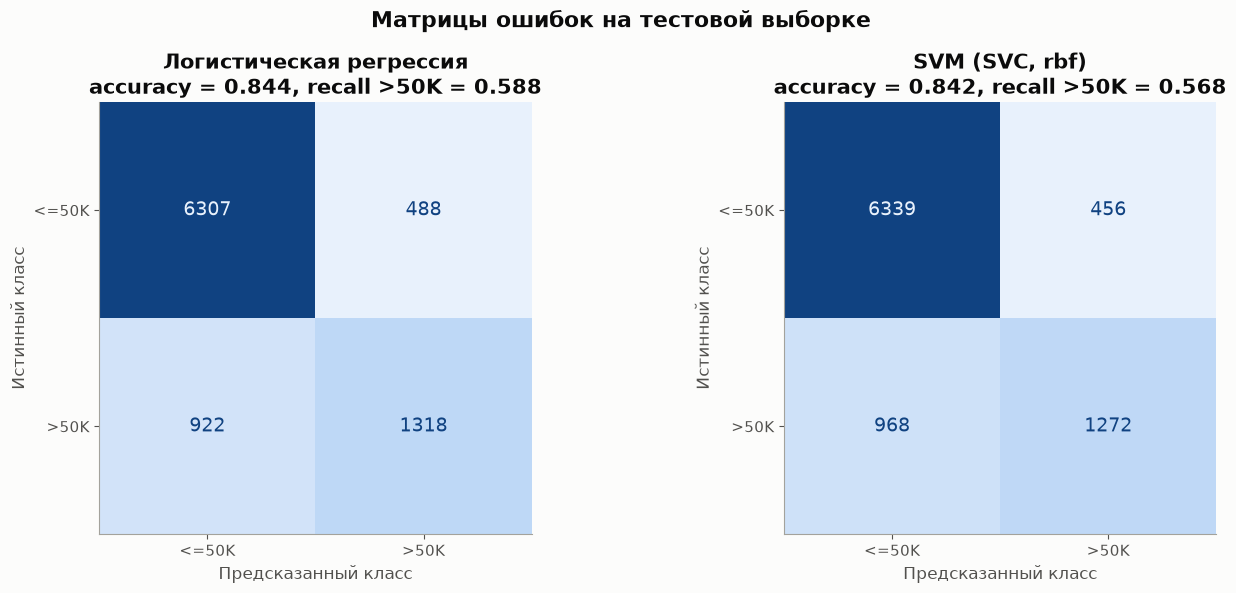

In [21]:
cmap_blue = LinearSegmentedColormap.from_list("blue_seq", ["#e8f1fc", "#86b6ef", "#2a78d6", "#104281"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, y_pred) in zip(axes, [("Логистическая регрессия", y_pred_lr), ("SVM (SVC, rbf)", y_pred_svm)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=target_names, cmap=cmap_blue,
        values_format="d", colorbar=False, ax=ax, text_kw={"fontsize": 14})
    ax.set_title(f"{name}\naccuracy = {(y_pred == y_test).mean():.3f}, recall >50K = {recall_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    ax.grid(False)
fig.suptitle("Матрицы ошибок на тестовой выборке", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

**Промежуточный итог.** Обе модели предсказывают значительно лучше базового уровня (~75%): у логистической регрессии accuracy ≈ 84,4%, у SVM ≈ 84,2%. Разница между ними около 0,15 п.п., на тестовой выборке из 9 035 объектов это 14 ответов, то есть в пределах статистического шума.

Матрицы ошибок показывают главную слабость обеих моделей. Класс `<=50K` распознаётся хорошо (recall ≈ 0,93), а из людей с доходом `>50K` модели находят только 57–59%. Остальных они относят к большинству.

## 6. Дополнительные эксперименты

### 6.1. Альтернативная обработка пропусков: категория `Unknown`

Повторим подготовку данных, но вместо удаления строк заменим пропуски новой категорией `Unknown`. Обучим ту же логистическую регрессию.

In [22]:
df_raw = pd.concat([df_train_part, df_test_part], ignore_index=True)
df_raw["income"] = df_raw["income"].str.rstrip(".")
df_unknown = df_raw.replace("?", "Unknown").drop_duplicates()

def prepare(data):
    X_ = data.drop(columns=["income", "education", "fnlwgt"]).copy()
    X_["sex"] = (X_["sex"] == "Male").astype(int)
    X_ = pd.get_dummies(X_, columns=nominal_cols, drop_first=True, dtype=int)
    return X_, (data["income"] == ">50K").astype(int)

X_u, y_u = prepare(df_unknown)
X_u_train, X_u_test, y_u_train, y_u_test = train_test_split(
    X_u, y_u, test_size=0.2, random_state=RANDOM_STATE, stratify=y_u)

log_reg_u = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_u_train, y_u_train)
print(f"Размер датасета: {X_u.shape[0]} строк (вместо {X.shape[0]}), признаков: {X_u.shape[1]}")
print(f"Логистическая регрессия, пропуски -> 'Unknown': score = {log_reg_u.score(X_u_test, y_u_test):.4f}")
print(f"Логистическая регрессия, пропуски удалены:      score = {acc_lr:.4f}")

Размер датасета: 48790 строк (вместо 45175), признаков: 84
Логистическая регрессия, пропуски -> 'Unknown': score = 0.8557
Логистическая регрессия, пропуски удалены:      score = 0.8439


Точность выросла примерно на 1,2 п.п., но напрямую сравнивать нельзя: тестовые выборки разные. В варианте с `Unknown` в тест попали и люди с пропусками, а среди них доход `>50K` встречается реже. Предсказывать для них проще, отсюда часть прироста. Главный плюс подхода в другом: сохраняются 7,4% данных, и модель умеет работать с новыми записями, в которых есть пропуски. Модель, обученная на данных без пропусков, на таких записях не сработает.

### 6.2. Учёт дисбаланса классов и другие модели

Сравним на той же обучающей и тестовой выборке:

- логистическую регрессию с `class_weight="balanced"`: ошибки на редком классе `>50K` штрафуются сильнее;
- линейный SVM (`LinearSVC`), чтобы проверить, даёт ли что-то нелинейное RBF-ядро;
- градиентный бустинг (`HistGradientBoostingClassifier`) как ориентир, чего можно добиться другим классом моделей.

In [23]:
extra_models = {
    "Логистическая регрессия, class_weight='balanced'":
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Линейный SVM (LinearSVC)":
        make_pipeline(StandardScaler(), LinearSVC(random_state=RANDOM_STATE)),
    "Градиентный бустинг (HistGradientBoosting)":
        HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in extra_models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    y_pred = model.predict(X_test)
    rows.append({"Модель": name, "Accuracy test (score)": model.score(X_test, y_test),
                 "Precision >50K": precision_score(y_test, y_pred),
                 "Recall >50K": recall_score(y_test, y_pred),
                 "F1 >50K": f1_score(y_test, y_pred), "Время обучения, с": elapsed})

comparison = pd.concat([results.drop(columns="Accuracy train").iloc[1:],
                        pd.DataFrame(rows).set_index("Модель")])
comparison.round(4)

,Accuracy test (score),Precision >50K,Recall >50K,F1 >50K,"Время обучения, с"
Модель,,,,,
Логистическая регрессия,0.8439,0.7298,0.5884,0.6515,1.3764
"SVM (SVC, rbf)",0.8424,0.7361,0.5679,0.6411,92.2272
"Логистическая регрессия, class_weight='balanced'",0.8060,0.5753,0.8304,0.6797,0.6315
Линейный SVM (LinearSVC),0.8447,0.7360,0.5826,0.6504,2.0563
Градиентный бустинг (HistGradientBoosting),0.8655,0.7846,0.6308,0.6993,2.0230


**Что показывают эксперименты**

- **`class_weight="balanced"`** заметно повышает полноту по классу `>50K`, с 0,59 до 0,83. Модель находит больше людей с высоким доходом, а F1 по этому классу растёт. Accuracy при этом падает примерно до 80,6%: модель чаще ошибается на большинстве. Какой вариант лучше, зависит от бизнес-задачи и цены каждого вида ошибки.
- **Линейный SVM** даёт ту же точность, что SVM с RBF-ядром, и обучается в десятки раз быстрее. Без подбора параметров нелинейное ядро ничего не добавляет: данные после one-hot кодирования почти линейно разделимы в той мере, в какой вообще разделимы.
- **Градиентный бустинг** с параметрами по умолчанию даёт ≈ 86,6% accuracy и лучший F1 по `>50K`. Это ещё около 2 п.п. к линейным моделям: деревья сами находят нелинейности (возраст, `capital-gain`) и взаимодействия признаков.

## 7. Выводы

### a) Какие преобразования были сделаны с данными

1. Объединили файлы `adult.data` и `adult.test` из архива UCI (48 842 записи), убрали пробелы в значениях и точку в метках класса тестового файла.
2. Нашли пропуски: в датасете они записаны как `?` в признаках `workclass`, `occupation` и `native-country`. Заменили их на `NaN` и **удалили строки с пропусками** (3 620 строк, 7,4%). Удалили 47 полных дубликатов. Осталось **45 175 записей**.
3. Удалили признак `education` (дублирует порядковый `education-num`) и `fnlwgt` (технический вес выборки, от класса не зависит).
4. Закодировали целевую переменную (`>50K` → 1, `<=50K` → 0) и бинарный признак `sex`. Шесть номинальных признаков перевели в one-hot кодирование. Получилось **80 признаков**.
5. Разделили данные на обучающую (80%, 36 140 записей) и тестовую (20%, 9 035 записей) выборки со стратификацией по классу.
6. Масштабировали признаки `StandardScaler` внутри пайплайна. Масштаб обучался только на обучающей выборке.

### b) Сравнение точности моделей

| Модель | Accuracy на тесте (`score`) |
|---|---|
| Базовый уровень (всегда `<=50K`) | 0,752 |
| **Логистическая регрессия** | **0,844** |
| **SVM (SVC, ядро RBF)** | **0,842** |

Точность моделей практически одинакова, у логистической регрессии она на 0,15 п.п. выше. Это 14 правильных ответов из 9 035, в пределах случайных колебаний. Переобучения у обеих моделей нет: точность на обучающей выборке выше тестовой не более чем на 1–2 п.п.

На практике логистическая регрессия здесь удобнее. Она обучается меньше чем за секунду (SVM несколько десятков секунд), сразу выдаёт вероятности классов и интерпретируется через коэффициенты признаков. SVM обучается медленнее, а с ростом данных время растёт сверхлинейно.

### c) Справились ли модели с задачей

**Частично.** Обе модели явно лучше базового уровня: на ~9 п.п. по accuracy, ошибка ~15,6% против ~24,8%. Результат близок к ориентирам из описания датасета (ошибка 14–16% у C4.5, Naive Bayes и других алгоритмов). Как базовое решение модели годятся.

Но высокая accuracy во многом держится на хорошо предсказуемом большинстве. Для класса `>50K` полнота всего ~0,57–0,59: **примерно 4 из 10 людей с высоким доходом модели не находят**. Если задача в поиске именно таких людей (таргетинг премиальных продуктов, скоринг), этого недостаточно.

### \* Как улучшить результат

1. **Учесть дисбаланс классов**: `class_weight="balanced"`, подбор порога вероятности под нужный баланс precision/recall, oversampling (SMOTE). Эксперимент 6.2 поднял recall `>50K` с 0,59 до 0,83.
2. **Подобрать гиперпараметры** через `GridSearchCV` / `RandomizedSearchCV` с кросс-валидацией: `C` для логистической регрессии; `C`, `gamma` и тип ядра для SVM. Оценивать модели по F1 или ROC-AUC, а не только по accuracy.
3. **Сохранить данные с пропусками**: заменять их категорией `Unknown` вместо удаления строк (эксперимент 6.1).
4. **Доработать признаки**: биннинг или полиномиальные признаки для возраста (зависимость нелинейная), бинарные флаги `capital-gain > 0` / `capital-loss > 0`, укрупнение редких стран (`native-country`: 91% — США) и редких категорий, взаимодействия признаков (например, семейное положение × образование).
5. **Попробовать модели, которые сами находят нелинейности и взаимодействия**: градиентный бустинг (HistGradientBoosting, CatBoost, LightGBM, XGBoost), случайный лес. Даже без настройки бустинг дал ≈ 86,6% (эксперимент 6.2).